# Your own pages: does a question need the picture?

Run the figure-only test and three retrieval arms on up to 20 pages and 10 questions of your own,
with the cost of each step printed before it runs.

The comparison notebook, `01_parse_enrich_or_embed.ipynb`, asks this question on 1,000 filing pages.
This notebook asks it on yours, in three steps:

1. The figure-only test. Your model answers each question twice from the page that holds the answer:
   once from Docling's text of the page and once from an image of it. A question answered from the
   image and not from the text needs the picture.
2. Enrichment. Your model describes each picture and summarises each complex table, and the
   descriptions are indexed as text.
3. Three arms over your pages: text chunks (`T`), enriched text chunks (`E2`), and ColModernVBERT page
   retrieval with your model reading the page images (`VV`).

It ships with a six-page demonstration document, an annual review of a fictional freight railway that
this notebook's code draws (`vdocs.own_pages.write_demo_pdf`). Three of its charts print values that
appear nowhere in the text, one chart repeats its headline value in the text, one page holds a table,
and one page holds only prose. The committed outputs are the reference run on the on-prem models.

In [1]:
import os
import sys
import warnings
from pathlib import Path


sys.path.insert(0, str(Path.cwd()))

from aieng.advanced_rag import spend
from aieng.advanced_rag.models import choose_models
from vdocs.own_pages import DEMO_NAME, DEMO_QUESTIONS, ROWS, OwnPages, share
from vdocs.pages import render_page


# Quiet the model downloaders' progress bars and notices in the committed outputs.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message="IProgress not found")

# Model calls and the CPU page embedding run only with this on. Off, every step
# reads the reference run for the demonstration document.
RUN_EXPENSIVE = False

MODELS = choose_models(show=True)

# Replace with your own PDFs (20 pages in all at most) and up to 10 questions.
# "page" is the zero-based page of the first PDF that answers the question, or
# ("<pdf_stem>", page) for another PDF, or None when your pages do not answer it.
PDFS = [Path("demo") / f"{DEMO_NAME}.pdf"]
QUESTIONS = DEMO_QUESTIONS

own = OwnPages(PDFS, QUESTIONS, MODELS, live=RUN_EXPENSIVE)

family google
  generation  gemini-3.5-flash-lite   $0.30 in / $2.50 out per 1M tokens
  judging     gemini-3.8-flash        $0.75 in / $3.75 out per 1M tokens; introductory price
  extraction  gemini-3.5-flash-lite   $0.30 in / $2.50 out per 1M tokens
  embeddings  BAAI/bge-small-en-v1.5  local
key budget unknown (the proxy did not answer)


## Parse the pages

Docling converts each PDF with OCR off and table structure on, the settings the `table_structured_reasoning` ingestion uses for born-digital
filings. Turn OCR on in `OwnPages.parse` for scanned pages. The parse runs on the CPU, takes a few
seconds a page, and is cached.

6 pages, 3 pictures, 1 tables
own-00  figure  larkspur_freight_review#p001       How many million tonnes of freight did Larkspur Freight Rail carry in 2022?
own-01  figure  larkspur_freight_review#p002       What share of Larkspur Freight Rail's 2024 revenue came from the Automotive segment?
own-02  figure  larkspur_freight_review#p004       What was Larkspur Freight Rail's on-time delivery rate in the third quarter of 2024?
own-03  figure  larkspur_freight_review#p002       What share of Larkspur Freight Rail's 2024 revenue came from the Intermodal segment?
own-04  table   larkspur_freight_review#p003       What was the operating income of Larkspur Freight Rail's Prairie corridor in 2024?
own-05  table   larkspur_freight_review#p003       What revenue did Larkspur Freight Rail's Coastal corridor earn in 2023?
own-06  text    larkspur_freight_review#p005       How many reportable safety incidents did Larkspur Freight Rail record in 2024?
own-07  null    (not in these pages)            

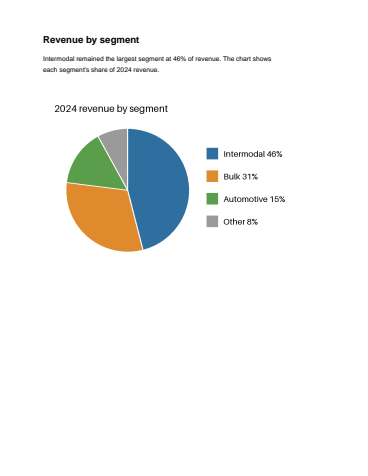

In [2]:
pages = own.parse()
found = own.elements()
print(
    f"{len(pages)} pages, {sum(e.kind == 'picture' for e in found)} pictures, "
    f"{sum(e.kind == 'table' for e in found)} tables"
)
for q in own.question_records():
    print(
        f"{q['query_id']}  {q['group']:<7} {', '.join(q['gold_pages']) or '(not in these pages)':<34} {q['question']}"
    )
render_page(own.corpus, pages[2], scale=0.6)

## Run the figure-only test

The cell prints the price on your generation model first. With `RUN_EXPENSIVE = False` it reads the
reference run and labels it with the model that built it.

In [3]:
print(own.estimate("figure-only test", MODELS.generation.model))
test = own.figure_only_test()
records = {q["query_id"]: q for q in own.question_records()}
print()
print(f"{'question':<9}{'kind':<8}{'text':>6}{'image':>7}  needs")
for qid, row in sorted(test.value.items()):
    needs = (
        "picture"
        if row["image"] and not row["text"]
        else ("either" if row["image"] else "text" if row["text"] else "neither")
    )
    print(
        f"{qid:<9}{records[qid]['group']:<8}{'yes' if row['text'] else 'no':>6}{'yes' if row['image'] else 'no':>7}  {needs}"
    )
figure_only = [r["image"] and not r["text"] for r in test.value.values()]
print(f"\nfigure-only share: {share(figure_only):.0%} of {len(figure_only)} answerable questions")

figure-only test on gemini-3.5-flash-lite: 16 calls, about 16,720 input tokens, est. $0.0066
figure-only-test reference artifact, built with Qwen3_8-27B on Vector's cluster at $0
                 14 calls, 9,126 prompt + 218 completion tokens
                 rebuilding with gemini-3.5-flash-lite: about 14 calls, est. $0.00 (set RUN_EXPENSIVE = True to rebuild)

question kind      text  image  needs
own-00   figure      no    yes  picture
own-01   figure      no    yes  picture
own-02   figure      no    yes  picture
own-03   figure     yes    yes  either
own-04   table      yes    yes  either
own-05   table      yes    yes  either
own-06   text       yes    yes  either

figure-only share: 43% of 7 answerable questions


Read the share before choosing a pipeline. When almost no question is figure-only, text parsing with
table-aware chunking is the default and figure work can wait. A question answered from neither is a
reading failure on the page that holds the answer, so no retrieval method fixes it.

## Describe pictures and summarise tables

This is the harness approach: one call per picture over 5% of its page and one per table with six or
more columns or a header spanning columns. Descriptions are paid once, at indexing, and again whenever
the prompt or the model changes.

In [4]:
print(own.estimate("enrichment", MODELS.extraction.model))
enriched = own.enrichment()
for eid, record in enriched.value["pictures"].items():
    print(f"\n{eid}\n{record['text'][:600]}")

enrichment on gemini-3.5-flash-lite: 3 calls, about 2,700 input tokens, est. $0.0031
enrichment reference artifact, built with Qwen3_8-27B on Vector's cluster at $0
           3 calls, 2,557 prompt + 382 completion tokens
           rebuilding with gemini-3.5-flash-lite: about 3 calls, est. $0.00 (set RUN_EXPENSIVE = True to rebuild)

larkspur_freight_review|#/pictures/0
Type: bar chart

The image shows a vertical bar chart with five bars, one for each year from 2020 to 2024. There are no visible axis titles, units, legend, or chart title/subtitle/caption/footnote. The values are printed directly above each bar.

| Year | Value |
|------|-------|
| 2020 | 18.4 |
| 2021 | 19.9 |
| 2022 | 21.2 |
| 2023 | 22.7 |
| 2024 | 24.1 |

larkspur_freight_review|#/pictures/1
Type: pie chart

The image displays a pie chart with a legend on the right side. There is no visible title, subtitle, caption, or footnote within the image itself.

The chart is divided into four segments, each corresponding to

## Compare three arms on your questions

`T` and `E2` embed chunks with `bge-small-en-v1.5` in seconds. `VV` embeds every page image and every
question with ColModernVBERT on the CPU, which takes tens of seconds for each page and each question on
a shared CPU. The next cell prints the measured rate. With a GPU and `onnxruntime-gpu`, the same model
embeds a page in under a second.

In [5]:
costs = own.visual_costs()
print(
    f"ColModernVBERT on the CPU: {costs['seconds_per_page']:.1f} s per page, "
    f"{costs['seconds_per_query']:.1f} s per question, index {costs['index_megabytes']} MB"
)
rankings = own.page_rankings()
gold = {q["query_id"]: q["gold_pages"] for q in own.question_records() if q["gold_pages"]}
print(f"\n{'arm':<5}{'gold page first':>17}{'in top 3':>10}")
for arm in ROWS:
    first = sum(rankings[arm][q][:1] == g[:1] for q, g in gold.items())
    top3 = sum(bool(set(rankings[arm][q][:3]) & set(g)) for q, g in gold.items())
    print(f"{arm:<5}{first:>12} of {len(gold)}{top3:>6} of {len(gold)}")

ColModernVBERT on the CPU: 19.3 s per page, 37.2 s per question, index 1.8 MB



arm    gold page first  in top 3
T               0 of 7     7 of 7
E2              0 of 7     7 of 7
VV              0 of 7     7 of 7


In [6]:
for row in ROWS:
    print(own.estimate(row, MODELS.generation.model))
print()
verdicts = {row: own.verdicts(row).value for row in ROWS}
print()
print(f"{'question':<9}{'kind':<8}" + "".join(f"{row:>5}" for row in ROWS))
for qid in sorted(records):
    print(
        f"{qid:<9}{records[qid]['group']:<8}" + "".join(f"{'yes' if verdicts[row][qid] else 'no':>5}" for row in ROWS)
    )
print(f"{'correct':<17}" + "".join(f"{sum(verdicts[row].values()):>5}" for row in ROWS))

T on gemini-3.5-flash-lite: 8 calls, about 13,200 input tokens, est. $0.0048
E2 on gemini-3.5-flash-lite: 8 calls, about 13,200 input tokens, est. $0.0048
VV on gemini-3.5-flash-lite: 8 calls, about 26,400 input tokens, est. $0.0087

reader-answers reference artifact, built with Qwen3_8-27B on Vector's cluster at $0
               8 calls, 3,945 prompt + 111 completion tokens
               rebuilding with gemini-3.5-flash-lite: about 8 calls, est. $0.00 (set RUN_EXPENSIVE = True to rebuild)
answer-verdicts reference artifact, built with Qwen3_6-35B-A3B on Vector's cluster at $0
                rebuilding with gemini-3.8-flash: no estimate: the reference recorded no token counts (set RUN_EXPENSIVE = True to rebuild)
reader-answers reference artifact, built with Qwen3_8-27B on Vector's cluster at $0
               8 calls, 6,108 prompt + 174 completion tokens
               rebuilding with gemini-3.5-flash-lite: about 8 calls, est. $0.00 (set RUN_EXPENSIVE = True to rebuild)
answer-verd

The cover page ranks first for every question in every arm, because it names the company and every
topic the review covers, so read the top-3 column. Text chunks never cross a page here
(`per_page=True`), because short pages would otherwise share a chunk that counts only for its first
page.

On the demonstration document every arm reads with the same model, so a difference between columns
comes from what the reader saw. Eight questions are too few to rank the arms, so use the table to see which kinds of question each arm misses. A
figure-only question that `T` misses and `VV` answers is the case for page images or for enrichment,
and the `E2` column says whether descriptions written once at indexing close that gap for your pages.

Take the next step in `01_parse_enrich_or_embed.ipynb`: its decision guide covers scanned pages, dense
tables, citation needs, and where each family pays.

In [7]:
print(spend.report())

this run, estimated   est. $0.00 over 0 models
